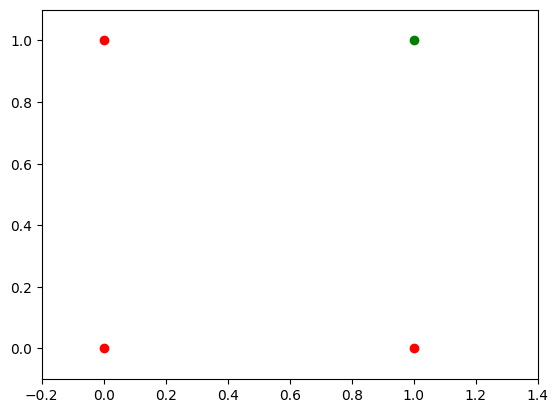

In [1]:
import matplotlib.pyplot as plt 
import numpy as np
fig, ax = plt.subplots() 
xmin, xmax = -0.2, 1.4
X = np.arange(xmin, xmax, 0.1) 
ax.scatter(0, 0, color="r")
ax.scatter(0, 1, color="r")
ax.scatter(1, 0, color="r")
ax.scatter(1, 1, color="g") 
ax.set_xlim([xmin, xmax]) 
ax.set_ylim([-0.1, 1.1])
m = -1
plt.show()

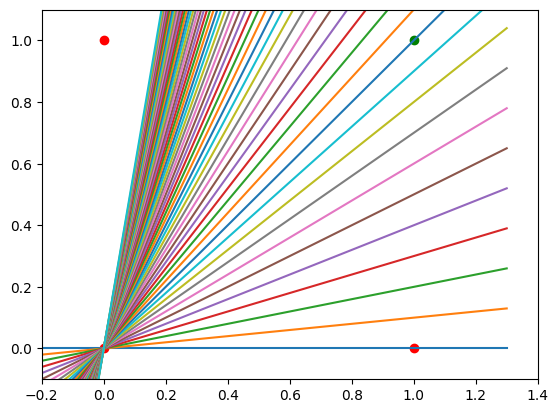

In [2]:
fig, ax = plt.subplots() 
xmin, xmax = -0.2, 1.4
X = np.arange(xmin, xmax, 0.1) 
ax.set_xlim([xmin, xmax]) 
ax.set_ylim([-0.1, 1.1])
m = -1
for m in np.arange(0, 6, 0.1): 
    ax.plot(X, m * X )
ax.scatter(0, 0, color="r")
ax.scatter(0, 1, color="r")
ax.scatter(1, 0, color="r")
ax.scatter(1, 1, color="g") 
plt.show()

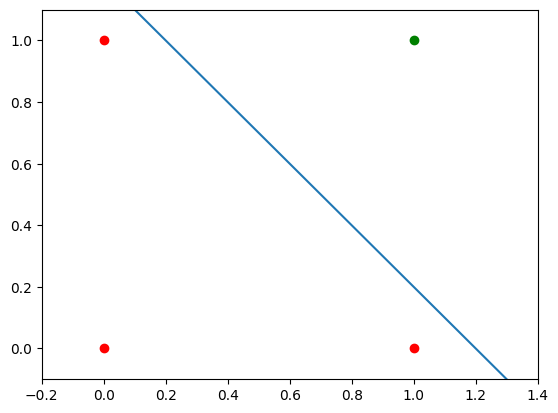

In [3]:
fig, ax = plt.subplots() 
xmin, xmax = -0.2, 1.4
X = np.arange(xmin, xmax, 0.1) 
ax.scatter(0, 0, color="r")
ax.scatter(0, 1, color="r")
ax.scatter(1, 0, color="r")
ax.scatter(1, 1, color="g") 
ax.set_xlim([xmin, xmax]) 
ax.set_ylim([-0.1, 1.1])
m, c = -1, 1.2
ax.plot(X, m * X + c ) 
plt.show()

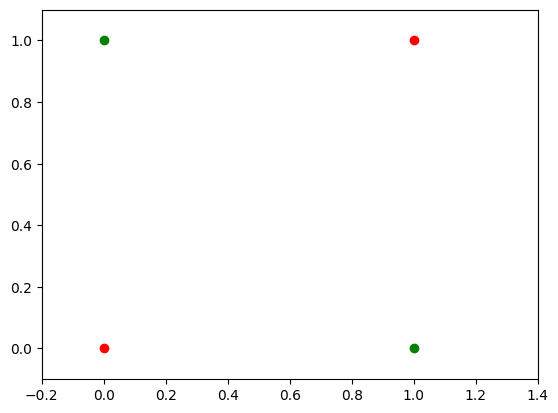

In [4]:
fig, ax = plt.subplots() 
xmin, xmax = -0.2, 1.4
X = np.arange(xmin, xmax, 0.1) 
ax.scatter(0, 0, color="r")
ax.scatter(0, 1, color="g")
ax.scatter(1, 0, color="g")
ax.scatter(1, 1, color="r") 
ax.set_xlim([xmin, xmax]) 
ax.set_ylim([-0.1, 1.1])
m = -1
plt.show()

In [6]:
from tabulate import tabulate
table = [(0,1), (1,0)]
headers = ["A", "NOT A"]
print(tabulate(table, headers = headers, tablefmt="pipe"))

|   A |   NOT A |
|----:|--------:|
|   0 |       1 |
|   1 |       0 |


In [7]:
import numpy as np
def unit_step(v):
    """ Step function. v must be a scalar """
    if v >= 0:
        return 1
    else:
        return 0
        
def perceptron(x, w, b):
    """ Function implemented by a perceptron with 
        weight vector w and bias b """
    v = np.dot(w, x) + b
    y = unit_step(v)
    return y
    
def NOT_percep(x):
    return perceptron(x, w=-1, b=0.5)
    
print("NOT(0) = {}".format(NOT_percep(0)))
print("NOT(1) = {}".format(NOT_percep(1)))

NOT(0) = 1
NOT(1) = 0


In [8]:
table = [(0, 0, 0),
(0, 1, 0),
(1, 0, 0),
(1, 1, 1)]
headers = ["A", "B", "A AND B"]
print(tabulate(table, headers=headers, tablefmt="pipe"))

|   A |   B |   A AND B |
|----:|----:|----------:|
|   0 |   0 |         0 |
|   0 |   1 |         0 |
|   1 |   0 |         0 |
|   1 |   1 |         1 |


In [9]:
def AND_percep(x):
    w = np.array([1, 1]) 
    b = -1.5
    return perceptron(x, w, b)
    
# Test
example1 = np.array([1, 1]) 
example2 = np.array([1, 0]) 
example3 = np.array([0, 1]) 
example4 = np.array([0, 0])
print("AND({}, {}) = {}".format(1, 1, AND_percep(example1)))
print("AND({}, {}) = {}".format(1, 0, AND_percep(example2)))
print("AND({}, {}) = {}".format(0, 1, AND_percep(example3)))
print("AND({}, {}) = {}".format(0, 0, AND_percep(example4)))


AND(1, 1) = 1
AND(1, 0) = 0
AND(0, 1) = 0
AND(0, 0) = 0


In [10]:
truth_table = [ 
    [0, 0, 0],
    [0, 1, 1],
    [1, 0, 1],
    [1, 1, 1]
]
headers = ["A", "B", "A OR B"]
table = tabulate(truth_table, headers, tablefmt="pipe") 
print(table)

|   A |   B |   A OR B |
|----:|----:|---------:|
|   0 |   0 |        0 |
|   0 |   1 |        1 |
|   1 |   0 |        1 |
|   1 |   1 |        1 |


In [11]:
def OR_percep(x):
    w = np.array([1, 1]) 
    b = -0.5
    return perceptron(x, w, b)
# Test
example1 = np.array([1, 1]) 
example2 = np.array([1, 0]) 
example3 = np.array([0, 1]) 
example4 = np.array([0, 0])
print("OR({}, {}) = {}".format(1, 1, OR_percep(example1)))
print("OR({}, {}) = {}".format(1, 0, OR_percep(example2)))
print("OR({}, {}) = {}".format(0, 1, OR_percep(example3)))
print("OR({}, {}) = {}".format(0, 0, OR_percep(example4)))


OR(1, 1) = 1
OR(1, 0) = 1
OR(0, 1) = 1
OR(0, 0) = 0


In [12]:
truth_table = [ 
    [0, 0, 0],
    [0, 1, 1],
    [1, 0, 1],
    [1, 1, 0]
]
headers = ["A", "B", "A XOR B"]
table = tabulate(truth_table, headers, tablefmt="pipe") 
print(table)

|   A |   B |   A XOR B |
|----:|----:|----------:|
|   0 |   0 |         0 |
|   0 |   1 |         1 |
|   1 |   0 |         1 |
|   1 |   1 |         0 |


In [13]:
def XOR_net(x):
    gate_1 = AND_percep(x) 
    gate_2 = NOT_percep(gate_1) 
    gate_3 = OR_percep(x)
    new_x = np.array([gate_2, gate_3]) 
    output = AND_percep(new_x)
    return output
    
print("XOR({}, {}) = {}".format(1, 1, XOR_net(example1)))
print("XOR({}, {}) = {}".format(1, 0, XOR_net(example2)))
print("XOR({}, {}) = {}".format(0, 1, XOR_net(example3)))
print("XOR({}, {}) = {}".format(0, 0, XOR_net(example4)))


XOR(1, 1) = 0
XOR(1, 0) = 1
XOR(0, 1) = 1
XOR(0, 0) = 0
